<a href="https://colab.research.google.com/github/Shibainulove/6070-001-202630/blob/main/WeeklyModules/Week12/Participation_Activity_Week12_Student_Performance_T_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12 Participation Activity: measuring a p-value with a t-test

**Qingan Xu**

The Student Performance Data Set has the math, reading and writing scores of 1,000 students, with their gender, whether they took a test preparation course, and some background information. This notebook uses t-tests to answer two questions:

1. Is there a statistically significant difference between **males who took the test preparation course** and other students?
2. Are there any other differences of interest?

Every test is two-tailed, at a significance level of α = 0.05.

## Setup

In [1]:
# Colab setup (Git_Key method). Opening this notebook from GitHub in Colab brings in only the
# .ipynb file, not the data file next to it. In Colab, this cell clones the repository with the
# GitHub token saved in Colab Secrets as Git_Key, then moves into this notebook's folder so the
# relative file paths below work as they do locally. If the CSV has already been uploaded to the
# Colab session, or the notebook runs locally, it uses that file and clones nothing.
import os
import subprocess
from pathlib import Path

GITHUB_USER = 'Shibainulove'
REPO = '6070-001-202630'
NOTEBOOK_DIR = 'WeeklyModules/Week12'  # this notebook's folder in the repository
DATA_FILE = 'Student Performance Data.csv'


def find_data_file():
    """The data file in the current folder, or None if it isn't there.

    A file downloaded from Canvas can come back renamed (a prefix added or spaces replaced),
    so any CSV whose name contains "student performance" also counts.
    """
    if Path(DATA_FILE).exists():
        return Path(DATA_FILE)
    simplify = lambda name: ''.join(ch for ch in name.lower() if ch.isalnum())
    matches = sorted(path for path in Path('.').glob('*.csv') if 'studentperformance' in simplify(path.stem))
    return matches[0] if matches else None


try:
    from google.colab import userdata
except ImportError:
    userdata = None  # not running in Colab

if userdata is None:
    print('Running locally: using the files next to this notebook')
elif find_data_file() is not None:
    print('Using the uploaded file', find_data_file())
else:
    repo_dir = Path('/content') / REPO
    if not repo_dir.exists():
        try:
            token = userdata.get('Git_Key')
        except Exception:  # no Git_Key secret, or this notebook was not given access to it
            token = ''  # cloning without a token still works while the repository is public
        login = f'{token}@' if token else ''
        url = f'https://{login}github.com/{GITHUB_USER}/{REPO}.git'
        clone = subprocess.run(['git', 'clone', '--depth', '1', url, str(repo_dir)],
                               capture_output=True, text=True,
                               env={**os.environ, 'GIT_TERMINAL_PROMPT': '0'})
        if clone.returncode != 0:
            details = clone.stderr.replace(token, '***') if token else clone.stderr
            raise RuntimeError('Could not clone the repository. Upload the CSV to this Colab session '
                               '(Files pane), or save a GitHub token that can read the repository in '
                               'Colab Secrets (key icon) as Git_Key and turn on notebook access.\n'
                               + details)
        # Remove the token from the clone's saved remote address
        subprocess.run(['git', '-C', str(repo_dir), 'remote', 'set-url', 'origin',
                        f'https://github.com/{GITHUB_USER}/{REPO}.git'], check=True)
    os.chdir(repo_dir / NOTEBOOK_DIR)
    print('Reading files from', Path.cwd())

Running locally: using the files next to this notebook


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05  # significance level for every test

# Chart colors, as in earlier weeks
SURFACE = '#fcfcfb'  # background
INK = '#0b0b0b'      # titles
INK_2 = '#52514e'    # subtitles, labels and numbers
AXIS = '#c3c2b7'     # axis lines
GRID = '#e1e0d9'     # gridlines
GRAY = '#898781'     # comparison groups, and intervals that cross 0
BLUE = '#2a78d6'     # males (the males who took the course are the focus)
ORANGE = '#eb6834'   # females

# Chart style. The fonts are tried in order: Arial (Windows and macOS), then Liberation Sans (Colab),
# which has the same letter widths as Arial, so the charts look and lay out the same in both.
# DejaVu Sans, matplotlib's own font, is the last resort.
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'axes.titlepad': 10, 'axes.labelsize': 10, 'axes.labelcolor': INK_2,
    'axes.labelpad': 8, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 6, 'ytick.major.pad': 6,
    'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID, 'grid.linewidth': 0.8,
    'legend.frameon': False, 'legend.fontsize': 9.5,
})
%config InlineBackend.figure_format = 'retina'  # sharp charts on high-resolution screens


def add_titles(fig, title, subtitle=None):
    """Lay out the figure, with a bold title and a gray subtitle above it, aligned left."""
    width, height = fig.get_size_inches()
    room = 0.68 if subtitle else 0.4  # inches kept free above the plots for the titles
    fig.tight_layout(rect=(0, 0, 1, 1 - room / height))
    left = 0.15 / width  # the left margin tight_layout leaves, about 0.15 inch
    fig.text(left, 1 - 0.1 / height, title, ha='left', va='top', fontsize=14, fontweight='bold', color=INK)
    if subtitle:
        fig.text(left, 1 - 0.42 / height, subtitle, ha='left', va='top', fontsize=10.5, color=INK_2)


def fmt_p(p):
    """A p-value as text, in scientific notation when it is below 0.001."""
    return f'{p:.3f}' if p >= 0.001 else f'{p:.1e}'


data_path = find_data_file()
if data_path is None:
    raise FileNotFoundError(f'Put {DATA_FILE} in {Path.cwd()}')
students = pd.read_csv(data_path)
print(data_path.name, students.shape)
students.head()

Student Performance Data.csv (1000, 10)


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


## 1. Check the data

Before testing, check that the file is complete and consistent: no missing values or duplicate rows, subject scores between 0 and 100, and a total score equal to math + reading + writing.

In [3]:
SUBJECTS = ['math score', 'reading score', 'writing score']
SCORES = SUBJECTS + ['total score']

print('Missing values:', students.isna().sum().sum())
print('Duplicate rows:', students.duplicated().sum())
print('Subject scores between 0 and 100:', students[SUBJECTS].stack().between(0, 100).all())
print('Total score = math + reading + writing for every student:',
      (students['total score'] == students[SUBJECTS].sum(axis=1)).all())

# Number of students by gender and test preparation course
pd.crosstab(students['gender'], students['test preparation course'], margins=True, margins_name='all')

Missing values: 0
Duplicate rows: 0
Subject scores between 0 and 100: True
Total score = math + reading + writing for every student: True


test preparation course,completed,none,all
gender,,,
female,184,334,518
male,174,308,482
all,358,642,1000


The data are complete: 1,000 students, with no gaps or duplicates, and every total adds up. 358 students took the test preparation course, 174 of them male.

The file also has an `admission prospect` column (low, medium or high). It looks like a banded version of the total score, so it isn't tested on its own. The next cell checks how closely it follows the bands.

In [4]:
# Admission prospect bands by total score: low up to 160, medium 161-220, high 221 and above
bands = pd.cut(students['total score'], [0, 160, 220, 300], labels=['low', 'medium', 'high'],
               include_lowest=True)
fits_band = bands.astype(str) == students['admission prospect']
print(f'Admission prospect matches the total-score band for {fits_band.sum()} of {len(students)} students')
students.loc[~fits_band, SCORES + ['admission prospect']]

Admission prospect matches the total-score band for 988 of 1000 students


,math score,reading score,writing score,total score,admission prospect
672,69,78,76,223,low
728,73,92,84,249,medium
729,53,39,37,129,high
738,81,71,73,225,low
750,71,69,68,208,high
769,58,60,57,175,low
809,59,54,51,164,high
844,40,65,64,169,high
845,90,85,84,259,low
892,50,67,73,190,low


For 988 students the prospect matches the band exactly. The other 12, all between rows 672 and 933, don't: row 845 has a total of 259 out of 300 but a "low" prospect, and row 729 has 129 but a "high" one. These look like data-entry errors in that column. They don't affect the t-tests, which use the scores themselves.

## 2. The groups being compared

The question compares **males who took the test preparation course** (`gender` is male and `test preparation course` is completed) with "others". That can be read two ways, so this notebook tests both:

- **A. All other students** (the question as worded): the other 826 students, both females and the males who didn't take the course.
- **B. Males who didn't take the course**: a like-for-like comparison. Holding gender fixed separates the course from differences between males and females, who score differently in reading and writing (part 5).

The total score (out of 300) is the main measure. The three subject scores (out of 100 each) show where a difference comes from.

In [5]:
is_male = students['gender'] == 'male'
took_course = students['test preparation course'] == 'completed'

male_course = students[is_male & took_course]
all_others = students[~(is_male & took_course)]
male_no_course = students[is_male & ~took_course]

groups = {
    'Males who took the course': male_course,
    'A. All other students': all_others,
    "B. Males who didn't take the course": male_no_course,
}
group_means = pd.DataFrame({name: group[SCORES].mean() for name, group in groups.items()}).T
group_means.insert(0, 'students', [len(group) for group in groups.values()])
group_means.round(1)

,students,math score,reading score,writing score,total score
Males who took the course,174,72.3,70.2,69.8,212.3
A. All other students,826,64.8,68.9,67.7,201.4
B. Males who didn't take the course,308,66.7,62.8,59.6,189.1


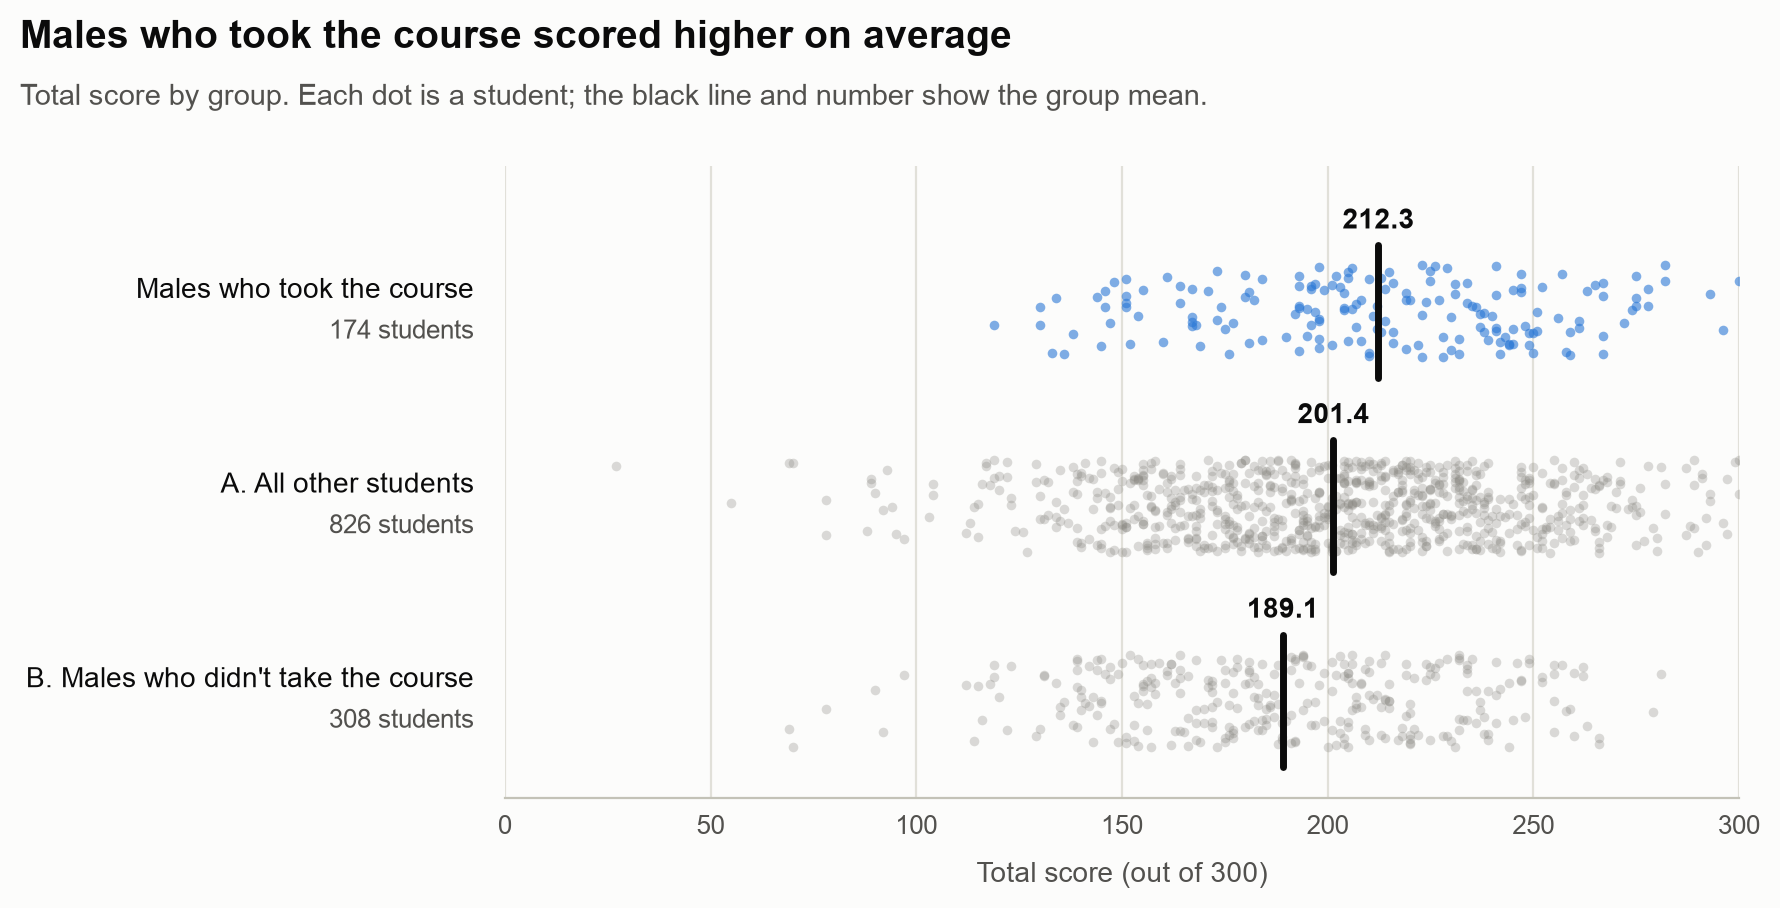

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
rng = np.random.default_rng(12)  # fixed seed, so the jitter is the same on every run
rows = list(groups)[::-1]        # first group at the top
row_label = ax.get_yaxis_transform()  # x in axes fractions, y in data units: for the group names
for y, name in enumerate(rows):
    totals = groups[name]['total score']
    focus = name == 'Males who took the course'
    ax.scatter(totals, y + rng.uniform(-0.24, 0.24, len(totals)), s=12, linewidths=0,
               color=BLUE if focus else GRAY, alpha=0.6 if focus else 0.3)
    ax.plot([totals.mean()] * 2, [y - 0.34, y + 0.34], color=INK, linewidth=2.5, solid_capstyle='round')
    ax.annotate(f'{totals.mean():.1f}', xy=(totals.mean(), y + 0.34), xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=10, fontweight='bold', color=INK)
    # The group's name, with its number of students underneath in gray
    ax.text(-0.025, y + 0.04, name, transform=row_label, ha='right', va='bottom', fontsize=10, color=INK)
    ax.text(-0.025, y - 0.04, f'{len(totals)} students', transform=row_label, ha='right', va='top',
            fontsize=9.5, color=INK_2)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_xlim(0, 300)
ax.set_ylim(-0.5, len(rows) - 0.25)
ax.grid(axis='x')
ax.set_xlabel('Total score (out of 300)')
add_titles(fig, 'Males who took the course scored higher on average',
           'Total score by group. Each dot is a student; the black line and number show the group mean.')
plt.show()

Males who took the course average 212.3, against 201.4 for all other students and 189.1 for males who didn't take the course. (Group B is part of group A.) Scores vary widely within every group and the groups overlap a lot, so a t-test is needed to judge whether the gaps between the means are bigger than chance would produce.

## 3. Check the t-test's assumptions

A two-sample t-test assumes:

1. **Independent observations.** Each student is counted once in each comparison.
2. **Roughly normal data, or large enough groups.** The smallest group has 174 students, so by the central limit theorem the group means are close to normally distributed even if the scores are somewhat skewed. The Q–Q plots and the normality test from the class notebook (`stats.normaltest`) check the scores themselves.
3. **Equal variances**, for Student's t-test. **Welch's t-test** (`equal_var=False`) drops this assumption and is the safer choice when the groups differ in size (174 vs 826), so this notebook uses it throughout. Levene's test still shows whether the variances differ.

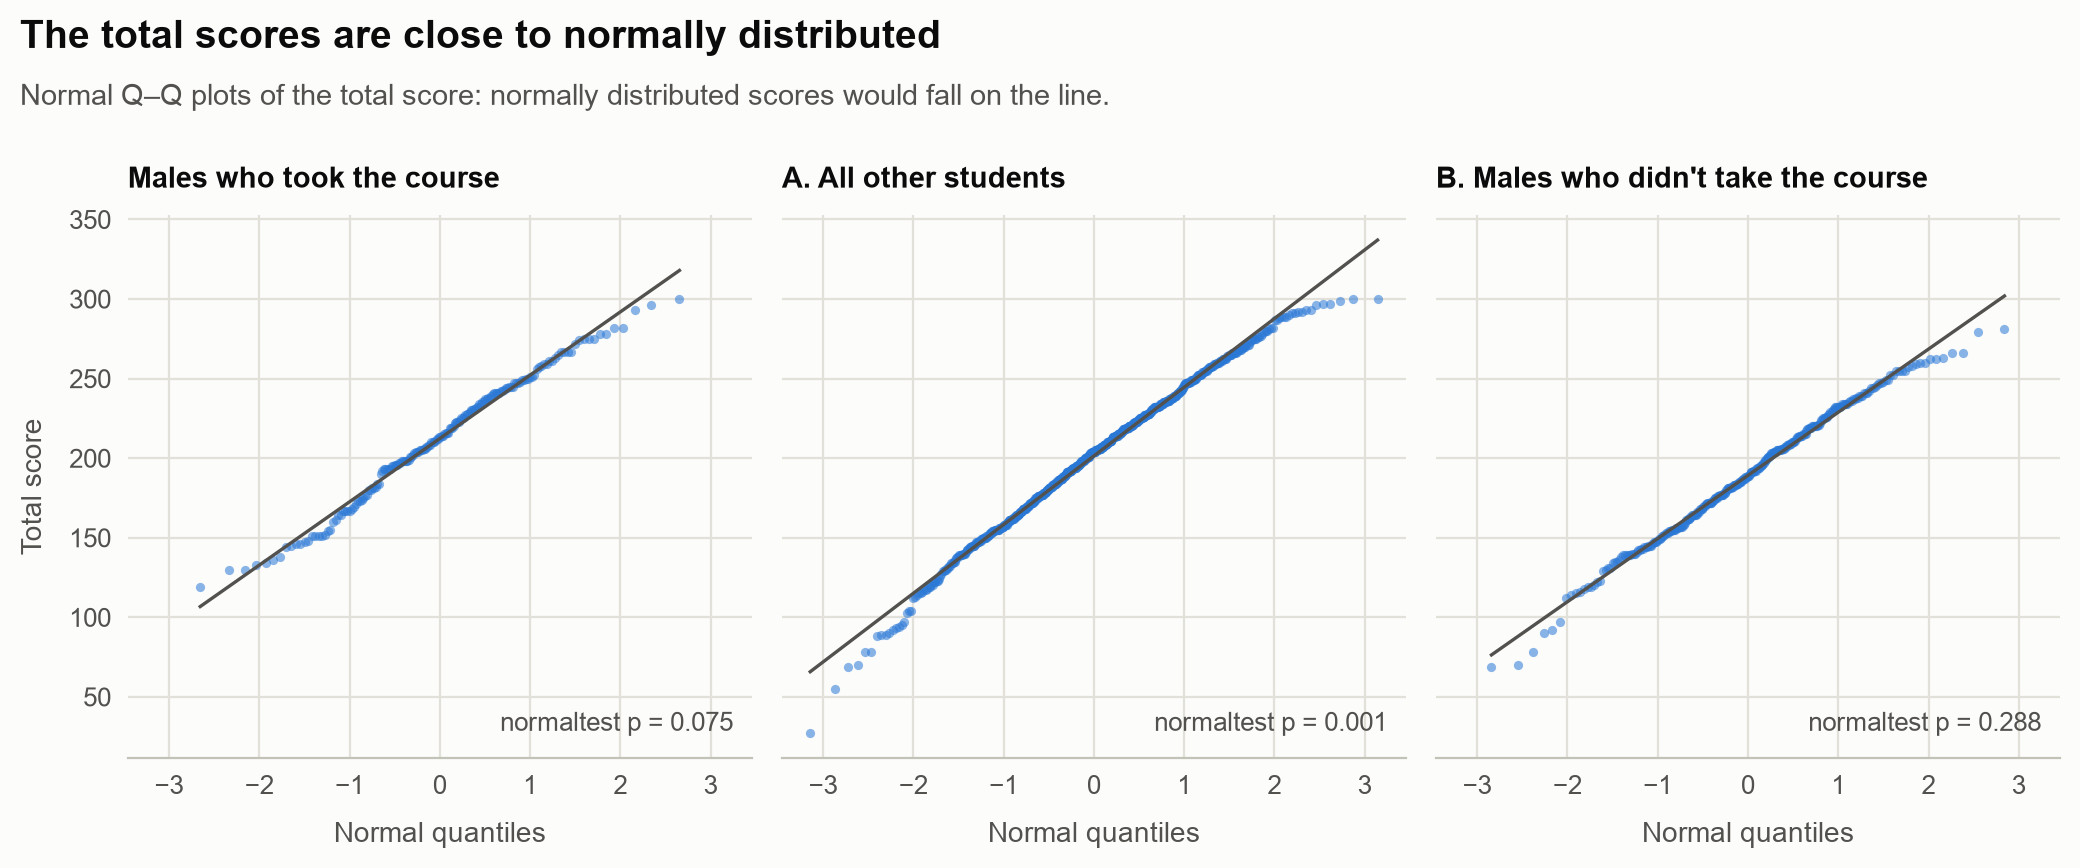

Levene's test, comparison A: p = 0.332
Levene's test, comparison B: p = 0.963


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 4.4), sharex=True, sharey=True)
for ax, (name, group) in zip(axes, groups.items()):
    (theoretical, ordered), (slope, intercept, _) = stats.probplot(group['total score'])
    ax.plot(theoretical, slope * theoretical + intercept, color=INK_2, linewidth=1.2)  # where normal data would lie
    ax.scatter(theoretical, ordered, s=11, color=BLUE, alpha=0.55, linewidths=0)
    ax.text(0.97, 0.04, f'normaltest p = {fmt_p(stats.normaltest(group["total score"]).pvalue)}',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9.5, color=INK_2)
    ax.set_title(name)
    ax.set_xlabel('Normal quantiles')
    ax.spines['left'].set_visible(False)
    ax.grid()
axes[0].set_ylabel('Total score')
add_titles(fig, 'The total scores are close to normally distributed',
           'Normal Q–Q plots of the total score: normally distributed scores would fall on the line.')
plt.show()

for label, other in [('A', all_others), ('B', male_no_course)]:
    levene = stats.levene(male_course['total score'], other['total score'])
    print(f"Levene's test, comparison {label}: p = {fmt_p(levene.pvalue)}")

- **Normality:** the points follow the line closely except at the ends. The highest totals bend below the line because no one can score above 300, and in the two comparison groups a few very low totals fall below it too: a slight left skew. The normality test rejects normality only for the large "all other students" group (p = 0.001): with 826 students, even a small skew is detectable. With groups this large the skew doesn't threaten the t-test, and the Mann–Whitney U test in part 4 checks the results without assuming normality.
- **Variances:** Levene's test finds no difference in variances (p = 0.332 and 0.963), so Welch's and Student's t-tests give almost the same answer here.

## 4. Question 2: males who took the course vs. others

### Comparison A, step by step

- **H0:** males who took the course have the same mean total score as all other students.
- **H1:** the two means are different.

The class notebook found a p-value by computing a t value and taking the area beyond it under a t distribution (`p = 2*td.sf(tval)`). Welch's two-sample t-test works the same way, with

$$t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$$

where $\bar{x}$ is a group's mean, $s^2$ its sample variance and $n$ its size. The degrees of freedom come from the Welch–Satterthwaite formula.

In [8]:
a = male_course['total score']
b = all_others['total score']

n_a, n_b = len(a), len(b)
var_a, var_b = a.var(ddof=1), b.var(ddof=1)  # sample variances
se = np.sqrt(var_a / n_a + var_b / n_b)      # standard error of the difference between the means
tval = (a.mean() - b.mean()) / se
df = (var_a / n_a + var_b / n_b) ** 2 / ((var_a / n_a) ** 2 / (n_a - 1) + (var_b / n_b) ** 2 / (n_b - 1))

td = stats.t(df)          # t distribution with Welch's degrees of freedom
p = 2 * td.sf(abs(tval))  # two-tailed: the area beyond |t| in both tails

print(f'Means: {a.mean():.2f} (males who took the course) vs {b.mean():.2f} (all other students)')
print(f'Difference: {a.mean() - b.mean():.2f} points, standard error {se:.2f}')
print(f't = {tval:.3f} with {df:.1f} degrees of freedom, p = {p:.4f}')

Means: 212.34 (males who took the course) vs 201.41 (all other students)
Difference: 10.94 points, standard error 3.36
t = 3.257 with 267.1 degrees of freedom, p = 0.0013


In [9]:
welch = stats.ttest_ind(a, b, equal_var=False)
print(f"scipy, Welch's t-test: t = {welch.statistic:.3f}, p = {welch.pvalue:.4f}")
print(f"Student's t-test (equal variances assumed): p = {stats.ttest_ind(a, b).pvalue:.4f}")

if welch.pvalue < ALPHA:
    print(f'p < {ALPHA}: reject H0. Males who took the course have a significantly different mean total score.')
else:
    print(f'p >= {ALPHA}: fail to reject H0. The difference is not statistically significant.')

scipy, Welch's t-test: t = 3.257, p = 0.0013
Student's t-test (equal variances assumed): p = 0.0021
p < 0.05: reject H0. Males who took the course have a significantly different mean total score.


The hand calculation and scipy agree: t = 3.26 and p = 0.0013. If the two groups really had the same mean, a gap of 10.9 points or more (in either direction) would turn up by chance in only about 1 sample in 800, so H0 is rejected.

### Every score, both comparisons

The function below runs the same test for any two groups and any score, and adds:

- the **95% confidence interval** for the difference between the means. When it excludes 0, the difference is significant at α = 0.05;
- **Cohen's d**, the difference measured in standard deviations, which shows how big it is whatever the sample size (about 0.2 is small, 0.5 medium and 0.8 large);
- the **Mann–Whitney U test** p-value, from a rank-based test that doesn't assume normal data, as a cross-check.

Running 8 tests instead of 1 raises the chance of a false positive, so the table also gives **Holm-adjusted p-values**, which correct for the number of tests. A result counts as significant when its adjusted p-value is below 0.05.

In [10]:
def compare(comparison, group_1, group_2, scores=SCORES):
    """Welch's t-test of each score, group_1 minus group_2, one row per score."""
    rows = []
    for score in scores:
        x, y = group_1[score], group_2[score]
        n_x, n_y = len(x), len(y)
        var_x, var_y = x.var(ddof=1), y.var(ddof=1)
        difference = x.mean() - y.mean()
        se = np.sqrt(var_x / n_x + var_y / n_y)
        df = (var_x / n_x + var_y / n_y) ** 2 / ((var_x / n_x) ** 2 / (n_x - 1) + (var_y / n_y) ** 2 / (n_y - 1))
        margin = stats.t(df).ppf(1 - ALPHA / 2) * se  # half-width of the 95% confidence interval
        pooled_sd = np.sqrt(((n_x - 1) * var_x + (n_y - 1) * var_y) / (n_x + n_y - 2))
        test = stats.ttest_ind(x, y, equal_var=False)
        rows.append({
            'comparison': comparison, 'score': score.removesuffix(' score'),
            'n 1': n_x, 'mean 1': x.mean(), 'n 2': n_y, 'mean 2': y.mean(),
            'difference': difference, 'CI low': difference - margin, 'CI high': difference + margin,
            't': test.statistic, 'df': df, 'p-value': test.pvalue,
            "Cohen's d": difference / pooled_sd,
            'Mann-Whitney p': stats.mannwhitneyu(x, y).pvalue,
        })
    return pd.DataFrame(rows)


def adjust(results):
    """Add Holm-adjusted p-values across all the tests in a table, and whether each test is significant."""
    results = results.copy()
    results['Holm p'] = multipletests(results['p-value'], method='holm')[1]
    results['significant'] = results['Holm p'] < ALPHA
    return results


def show(results):
    """The main columns of a results table, rounded, with the p-values written out."""
    table = results.set_index(['comparison', 'score'])[
        ['mean 1', 'mean 2', 'difference', 'CI low', 'CI high', 't', "Cohen's d",
         'p-value', 'Holm p', 'Mann-Whitney p', 'significant']].round(2)
    for column in ['p-value', 'Holm p', 'Mann-Whitney p']:
        table[column] = results[column].map(fmt_p).to_numpy()
    return table


q2 = adjust(pd.concat([
    compare('A. vs all other students', male_course, all_others),
    compare("B. vs males who didn't take the course", male_course, male_no_course),
], ignore_index=True))
show(q2)

mean 1  mean 2  difference  \
comparison                             score                                 
A. vs all other students               math      72.34   64.77        7.57   
                                       reading   70.21   68.95        1.26   
                                       writing   69.79   67.69        2.11   
                                       total    212.34  201.41       10.94   
B. vs males who didn't take the course math      72.34   66.69        5.65   
                                       reading   70.21   62.80        7.42   
                                       writing   69.79   59.65       10.14   
                                       total    212.34  189.13       23.21   

                                                CI low  CI high     t  \
comparison                             score                            
A. vs all other students               math       5.21     9.93  6.31   
                                       reading   -1.01     3.54  1.09   
                                       writing   -0.11     4.32  1.87   
                                       total      4.33    17.55  3.26   
B. vs males who didn't take the course math       3.01     8.29  4.21   
                                       reading    4.89     9.95  5.77   
                                       writing    7.69    12.59  8.14   
                                       total     15.83    30.60  6.18   

                                                Cohen's d  p-value   Holm p  \
comparison                             score                                  
A. vs all other students               math          0.51  1.2e-09  8.1e-09   
                                       reading       0.09    0.276    0.276   
                                       writing       0.14    0.062    0.124   
                                       total         0.26    0.001    0.004   
B. vs males who didn't take the course math          0.40  3.3e-05  1.3e-04   
                                       reading       0.55  1.8e-08  8.9e-08   
                                       writing       0.77  6.2e-15  5.0e-14   
                                       total         0.59  1.7e-09  1.0e-08   

                                               Mann-Whitney p  significant  
comparison                             score                                
A. vs all other students               math           5.5e-09         True  
                                       reading          0.310        False  
                                       writing          0.133        False  
                                       total            0.003         True  
B. vs males who didn't take the course math           6.5e-05         True  
                                       reading        4.4e-08         True  
                                       writing        1.0e-13         True  
                                       total          8.9e-09         True

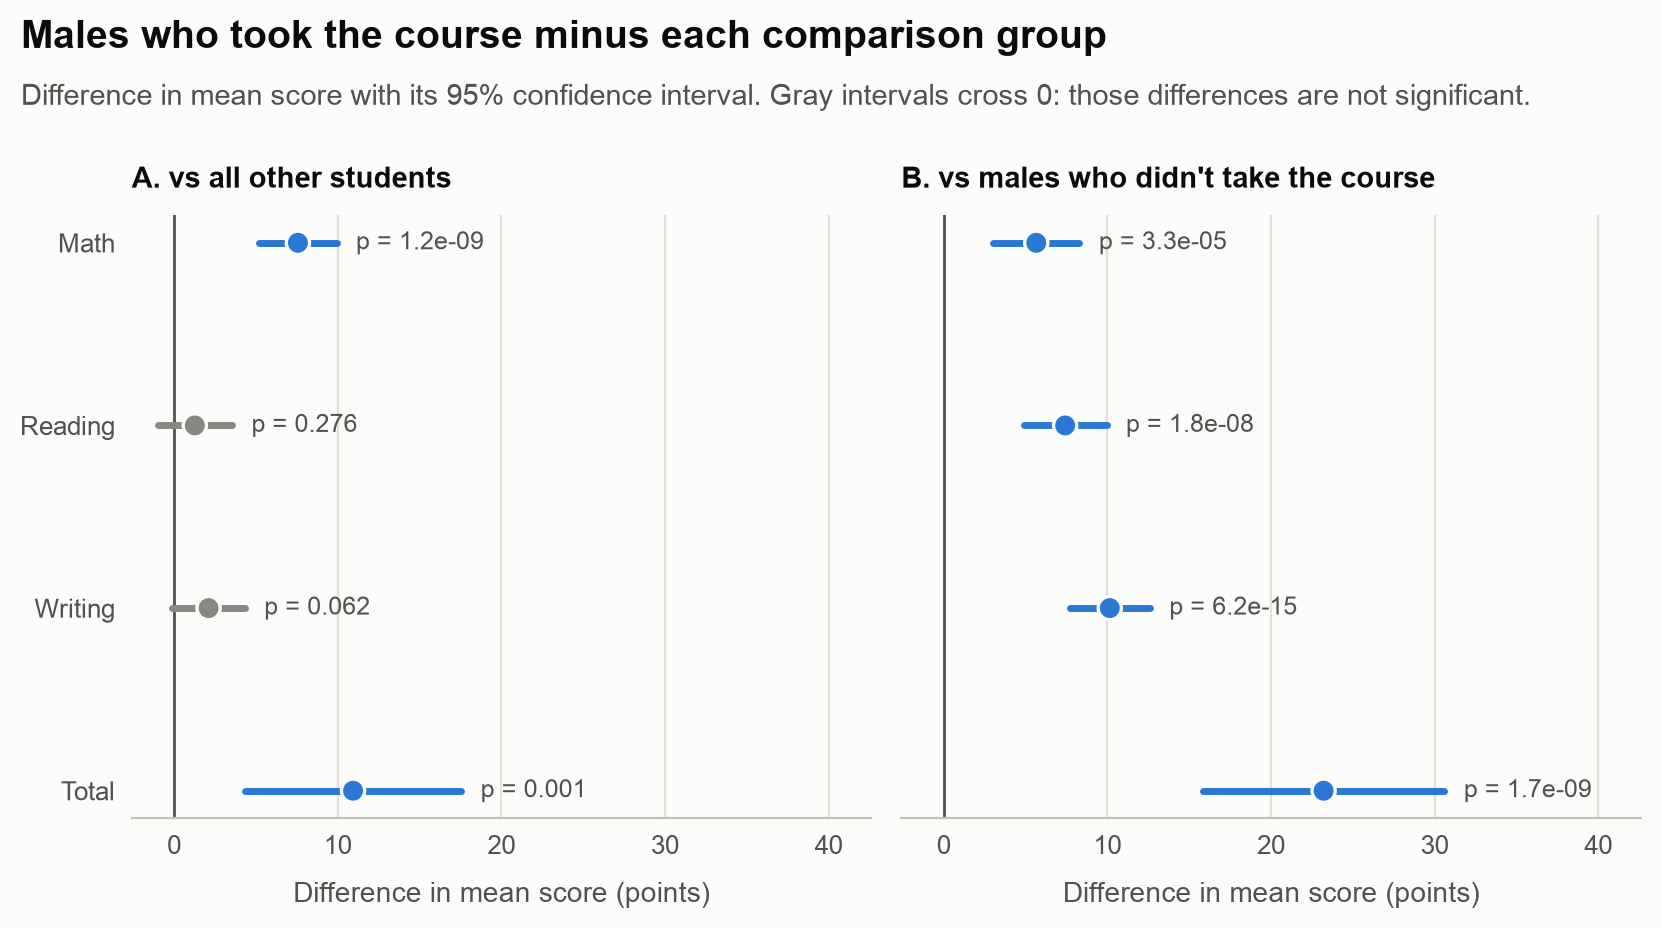

In [11]:
def plot_differences(results, panel_by, row_by, title, subtitle, p_labels=True):
    """Each difference between means as a dot with its 95% confidence interval, one panel per value of
    panel_by. Intervals that cross 0 (not significant, before adjustment) are gray."""
    panels = results[panel_by].unique()
    n_rows = results[row_by].nunique()
    fig, axes = plt.subplots(1, len(panels), figsize=(2.2 + 3.1 * len(panels), 0.55 * n_rows + 2.5),
                             sharex=True, sharey=True, squeeze=False)
    for ax, panel in zip(axes[0], panels):
        rows = results[results[panel_by] == panel]
        y = np.arange(len(rows))[::-1]  # first row at the top
        colors = np.where((rows['CI low'] > 0) | (rows['CI high'] < 0), BLUE, GRAY)
        ax.axvline(0, color=INK_2, linewidth=1)
        ax.hlines(y, rows['CI low'], rows['CI high'], colors=colors, linewidth=2.5, capstyle='round')
        ax.scatter(rows['difference'], y, s=70, color=colors, edgecolors=SURFACE, linewidths=1.2, zorder=3)
        if p_labels:
            for yi, high, p in zip(y, rows['CI high'], rows['p-value']):
                ax.annotate(f'p = {fmt_p(p)}', xy=(high, yi), xytext=(7, 0), textcoords='offset points',
                            va='center', fontsize=9, color=INK_2)
        ax.set_yticks(y, [label[0].upper() + label[1:] for label in rows[row_by]])
        ax.spines['left'].set_visible(False)
        ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=6, steps=[1, 2, 5, 10], integer=True))
        ax.grid(axis='x')
        ax.set_title(panel[0].upper() + panel[1:])
        ax.set_xlabel('Difference in mean score (points)')
    if p_labels:  # leave room on the right for the p-value labels
        left, right = axes[0, 0].get_xlim()
        axes[0, 0].set_xlim(left, right + 0.3 * (right - left))
    add_titles(fig, title, subtitle)
    plt.show()


plot_differences(q2, 'comparison', 'score', 'Males who took the course minus each comparison group',
                 'Difference in mean score with its 95% confidence interval. '
                 'Gray intervals cross 0: those differences are not significant.')

**A. Against all other students**, males who took the course scored **10.9 points higher in total** (212.3 vs 201.4; 95% CI 4.3 to 17.5; p = 0.0013, Holm-adjusted p = 0.004). The difference is significant but small (d = 0.26), and it comes almost entirely from **math** (+7.6 points, p = 1.2e-09). In **reading** (+1.3, p = 0.276) and **writing** (+2.1, p = 0.062) they aren't significantly different from everyone else: those intervals cross 0.

**B. Against males who didn't take the course**, the gap is twice as large and significant on every score: **+23.2 points in total** (212.3 vs 189.1; 95% CI 15.8 to 30.6; p = 1.7e-09; d = 0.59), made up of +5.7 in math, +7.4 in reading and +10.1 in writing.

**Why A and B differ:** "all other students" includes the 184 females who took the course, the highest-scoring group (223.4 in total), and females in general score higher than males in reading and writing (part 5). Against that mix, the males' reading and writing advantage disappears, while their math advantage remains.

The Mann–Whitney U test reaches the same conclusion as the t-test for all 8 comparisons, so the slight skew doesn't change any result.

### Could something other than the course explain the gap?

These are observational data: students chose whether to take the course, so a t-test shows that the groups differ, not that the course caused the difference. One check is whether the males who took the course were better off to begin with, on the two background measures in the file: lunch type (a free or reduced-price lunch is a common indicator of lower family income) and parents' education.

In [12]:
DEGREES = ["associate's degree", "bachelor's degree", "master's degree"]
background = (
    students[is_male]
    .assign(standard_lunch=lambda d: d['lunch'] == 'standard',
            parent_has_degree=lambda d: d['parental level of education'].isin(DEGREES))
    .groupby('test preparation course')[['standard_lunch', 'parent_has_degree']]
    .mean().mul(100).round(1)
)
background.columns = ['% with a standard lunch', '% whose parents have a degree']
background

,% with a standard lunch,% whose parents have a degree
test preparation course,,
completed,64.9,40.2
none,65.9,37.0


The two groups of males are almost identical on both measures (65% vs 66% with a standard lunch; 40% vs 37% whose parents have an associate's, bachelor's or master's degree), so neither explains the 23-point gap. Differences the data don't record, such as motivation, still could.

## 5. Question 3: other differences of interest

The same `compare` function, applied to other ways of splitting the students (group 1 minus group 2):

| Comparison | Group 1 | Group 2 | Why it's of interest |
|---|---|---|---|
| Gender: females vs males | females | males | Do females and males differ, and in which subjects? |
| Females: took the course vs didn't | females who took the course | females who didn't | Does the course gap seen for males also hold for females? |
| Lunch: standard vs free/reduced | standard lunch | free or reduced-price lunch | A common indicator of family income |
| Parents: degree vs no degree | parents have an associate's, bachelor's or master's degree | parents have no degree (some college, high school or some high school) | Family background |

Race/ethnicity is left out: its five groups are anonymized as A to E, and comparing five groups calls for an ANOVA rather than a t-test.

In [13]:
females = students[~is_male]
has_degree = students['parental level of education'].isin(DEGREES)
standard_lunch = students['lunch'] == 'standard'

q3 = adjust(pd.concat([
    compare('Gender: females vs males', females, students[is_male]),
    compare("Females: took the course vs didn't", students[~is_male & took_course], students[~is_male & ~took_course]),
    compare('Lunch: standard vs free/reduced', students[standard_lunch], students[~standard_lunch]),
    compare('Parents: degree vs no degree', students[has_degree], students[~has_degree]),
], ignore_index=True))
show(q3)

mean 1  mean 2  difference  \
comparison                         score                                 
Gender: females vs males           math      63.63   68.73       -5.10   
                                   reading   72.61   65.47        7.14   
                                   writing   72.47   63.31        9.16   
                                   total    208.71  197.51       11.20   
Females: took the course vs didn't math      67.20   61.67        5.52   
                                   reading   77.38   69.98        7.39   
                                   writing   78.79   68.98        9.81   
                                   total    223.36  200.63       22.73   
Lunch: standard vs free/reduced    math      70.03   58.92       11.11   
                                   reading   71.65   64.65        7.00   
                                   writing   70.82   63.02        7.80   
                                   total    212.51  186.60       25.91   
Parents: degree vs no degree       math      68.60   64.42        4.18   
                                   reading   72.20   67.16        5.04   
                                   writing   71.78   65.58        6.20   
                                   total    212.58  197.16       15.43   

                                            CI low  CI high      t  Cohen's d  \
comparison                         score                                        
Gender: females vs males           math      -6.95    -3.24  -5.40      -0.34   
                                   reading    5.38     8.89   7.97       0.50   
                                   writing    7.36    10.95  10.00       0.63   
                                   total      5.94    16.45   4.18       0.26   
Females: took the course vs didn't math       2.85     8.20   4.06       0.36   
                                   reading    4.97     9.81   6.01       0.53   
                                   writing    7.41    12.21   8.04       0.70   
                                   total     15.44    30.02   6.13       0.54   
Lunch: standard vs free/reduced    math       9.21    13.01  11.48       0.78   
                                   reading    5.12     8.89   7.29       0.49   
                                   writing    5.85     9.75   7.84       0.53   
                                   total     20.46    31.37   9.32       0.63   
Parents: degree vs no degree       math       2.28     6.09   4.31       0.28   
                                   reading    3.23     6.85   5.47       0.35   
                                   writing    4.33     8.07   6.51       0.42   
                                   total     10.12    20.73   5.71       0.37   

                                            p-value   Holm p Mann-Whitney p  \
comparison                         score                                      
Gender: females vs males           math     8.4e-08  3.4e-07        4.3e-07   
                                   reading  4.4e-15  5.7e-14        5.4e-15   
                                   writing  1.7e-22  2.6e-21        4.7e-23   
                                   total    3.2e-05  6.4e-05        1.3e-05   
Females: took the course vs didn't math     5.9e-05  6.4e-05        1.7e-04   
                                   reading  4.0e-09  2.8e-08        1.8e-08   
                                   writing  8.3e-15  9.9e-14        7.8e-14   
                                   total    2.0e-09  1.6e-08        9.5e-09   
Lunch: standard vs free/reduced    math     5.5e-28  8.9e-27        1.5e-26   
                                   reading  8.4e-13  8.4e-12        3.7e-12   
                                   writing  1.7e-14  1.9e-13        5.1e-14   
                                   total    1.6e-19  2.2e-18        1.8e-18   
Parents: degree vs no degree       math     1.8e-05  5.5e-05        1.5e-04   
                                   reading  6.0e-08  3.0e-07       

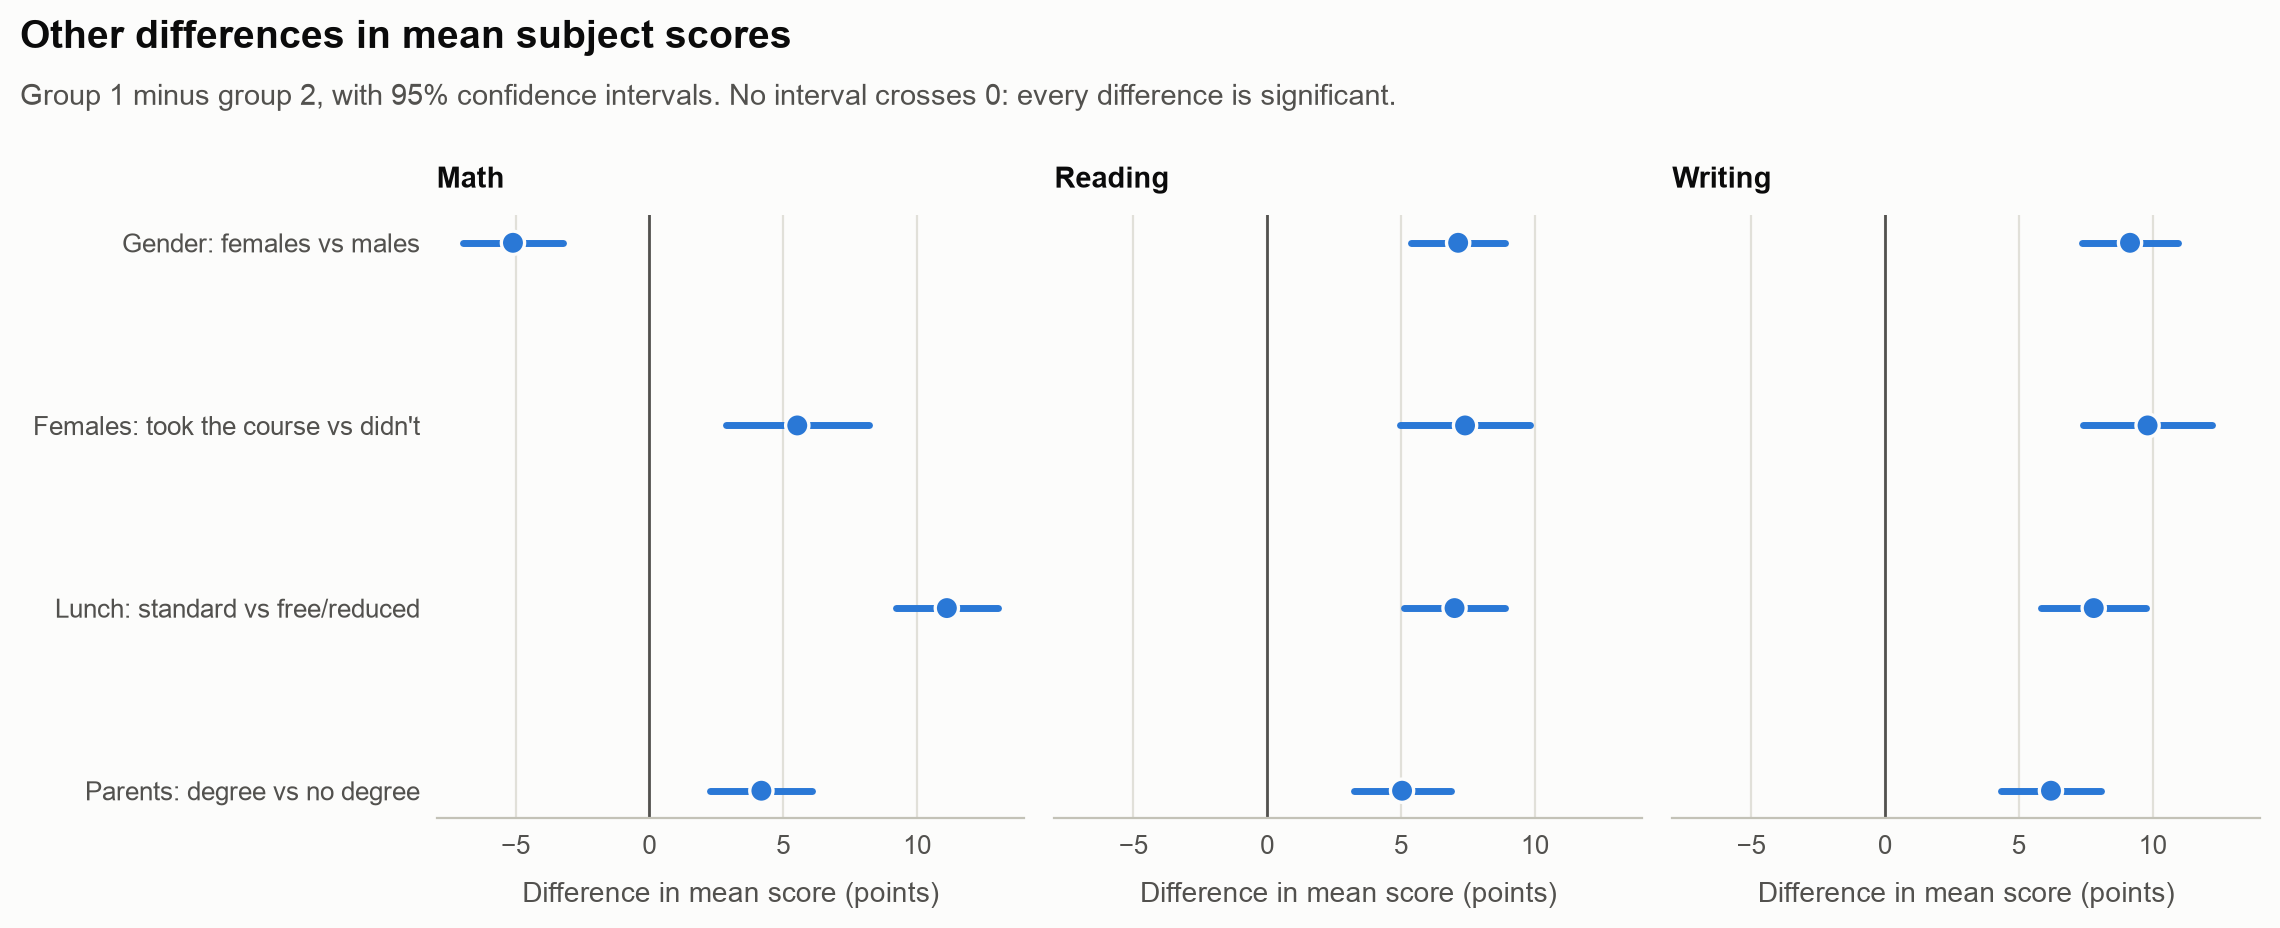

In [14]:
plot_differences(q3[q3['score'] != 'total'], 'score', 'comparison', 'Other differences in mean subject scores',
                 'Group 1 minus group 2, with 95% confidence intervals. '
                 'No interval crosses 0: every difference is significant.',
                 p_labels=False)

All 16 tests are significant, even after the Holm adjustment:

- **Gender works in opposite directions by subject.** Males score higher in **math** (68.7 vs 63.6, a 5.1-point gap, p = 8.4e-08), while females score higher in **reading** (+7.1) and **writing** (+9.2), and so in total (+11.2). One total score hides that reversal.
- **The course gap is about the same for females** as for males: females who took the course scored 22.7 points higher in total (p = 2.0e-09), against 23.2 points for males.
- **Lunch type shows the largest gap:** students with a standard lunch scored 25.9 points higher in total than students with a free or reduced-price lunch, and 11.1 points higher in math (d = 0.78, the largest effect in this notebook).
- **Parents' education** shows a smaller gap: students whose parents have a degree scored 15.4 points higher in total (d = 0.37).

### Does the course help males and females equally?

The male and female course gaps (23.2 and 22.7 points) look alike. To test whether they differ, a regression of the total score on gender, the course and their product (an **interaction**) estimates the difference between the two gaps. The p-value of each coefficient comes from a t-test too.

In [15]:
model_data = pd.DataFrame({
    'total': students['total score'],
    'male': is_male.astype(int),        # 1 for males, 0 for females
    'course': took_course.astype(int),  # 1 if the student took the course
})
model = smf.ols('total ~ male * course', data=model_data).fit()
print(f"Baseline (the intercept): females who didn't take the course average {model.params['Intercept']:.1f}")

coefficients = pd.DataFrame({
    'estimate': model.params, 'CI low': model.conf_int()[0], 'CI high': model.conf_int()[1],
    't': model.tvalues, 'p-value': model.pvalues.map(fmt_p),
}).drop(index='Intercept').rename(index={
    'male': 'Males minus females, without the course',
    'course': 'Course gap for females',
    'male:course': 'Extra course gap for males (interaction)',
})
coefficients.round(2)

Baseline (the intercept): females who didn't take the course average 200.6


,estimate,CI low,CI high,t,p-value
"Males minus females, without the course",-11.50,-17.86,-5.14,-3.55,4.0e-04
Course gap for females,22.73,15.34,30.12,6.04,2.2e-09
Extra course gap for males (interaction),0.48,-10.14,11.10,0.09,0.929


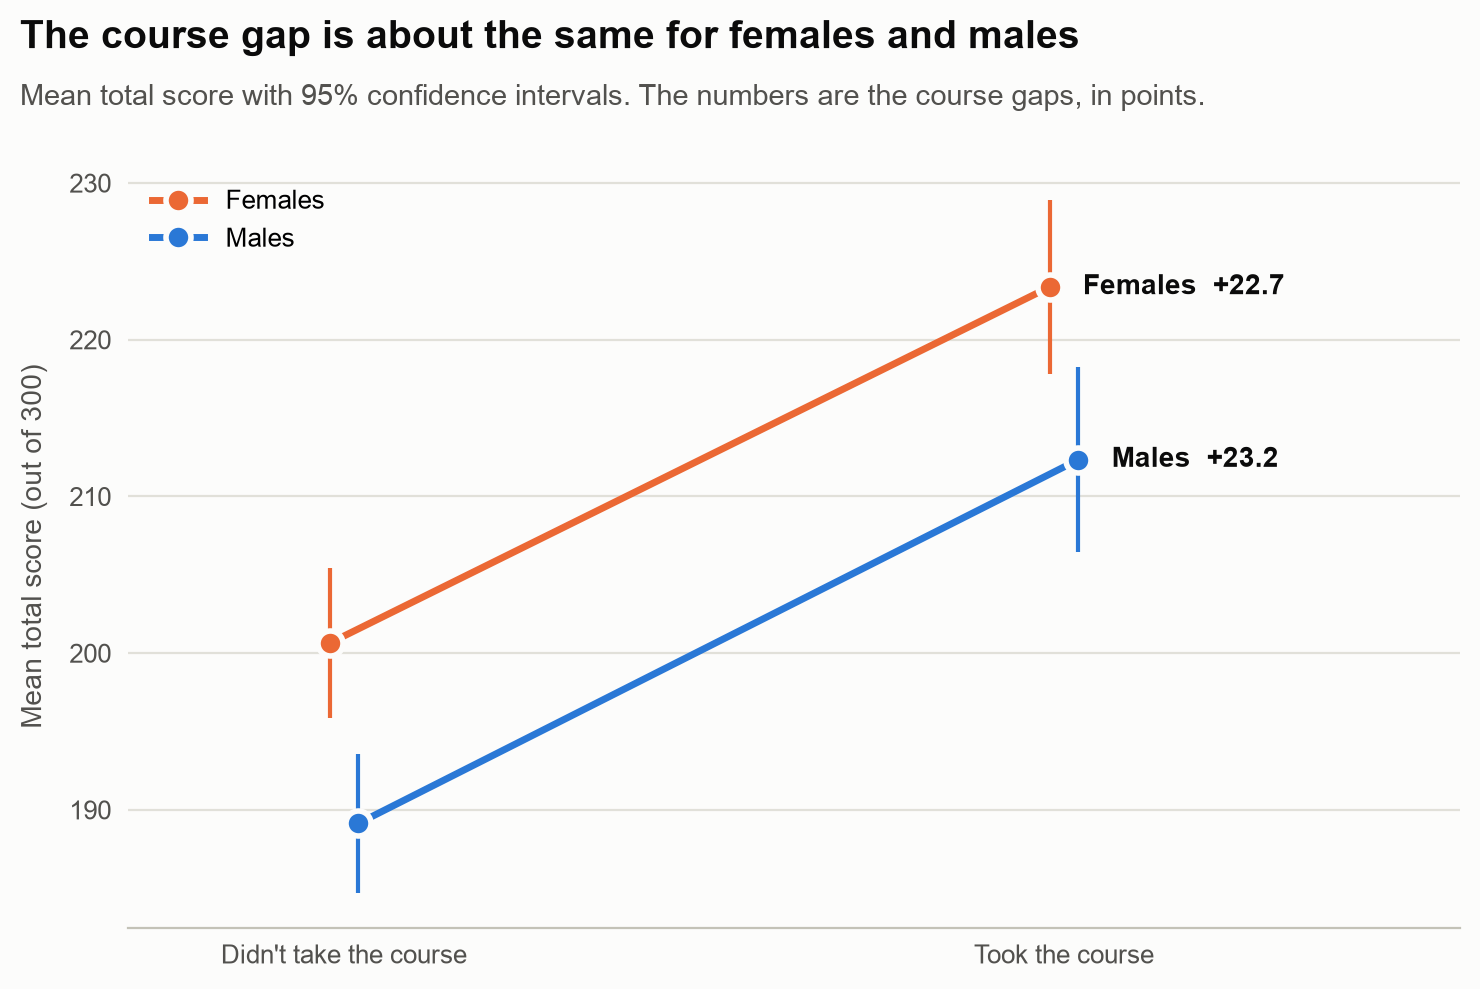

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 5))
x = np.array([0, 1])
for gender, color, shift in [('female', ORANGE, -0.02), ('male', BLUE, 0.02)]:  # shift keeps the intervals apart
    group = students[students['gender'] == gender]
    totals = [group.loc[group['test preparation course'] == level, 'total score'] for level in ['none', 'completed']]
    means = np.array([t.mean() for t in totals])
    margins = np.array([stats.t(len(t) - 1).ppf(1 - ALPHA / 2) * stats.sem(t) for t in totals])  # 95% CI half-widths
    ax.errorbar(x + shift, means, yerr=margins, color=color, linewidth=2.5, elinewidth=1.5, marker='o', markersize=9,
                markeredgecolor=SURFACE, markeredgewidth=2, label=f'{gender.capitalize()}s')
    ax.annotate(f'{gender.capitalize()}s  +{means[1] - means[0]:.1f}', xy=(1 + shift, means[1]),
                xytext=(12, 0), textcoords='offset points', va='center', fontsize=10, fontweight='bold', color=INK)
ax.set_xticks(x, ["Didn't take the course", 'Took the course'])
ax.set_xlim(-0.3, 1.55)
ax.set_ylabel('Mean total score (out of 300)')
ax.spines['left'].set_visible(False)
ax.grid(axis='y')
ax.legend(loc='upper left')
add_titles(fig, 'The course gap is about the same for females and males',
           'Mean total score with 95% confidence intervals. The numbers are the course gaps, in points.')
plt.show()

The interaction is only 0.5 points (95% CI −10.1 to 11.1; p = 0.929), so there is no evidence that the course gap differs between males and females: the two lines are almost parallel. Females score about 11 points higher than males whether or not they took the course, and the course gap is about 23 points for both.

That also explains question 2. Males who took the course beat males who didn't by 23 points, but they beat "all other students" by only 11, because that group includes the females who took the course.

## 6. Save the results

All 24 t-tests (8 for question 2 and 16 for question 3) go into one CSV file, one row per test.

In [17]:
results = pd.concat([q2.assign(question='Q2: males who took the course vs others'),
                     q3.assign(question='Q3: other differences')], ignore_index=True)
results = results[['question'] + [column for column in results.columns if column != 'question']]

RESULTS_FILE = 'Week12_t_test_results.csv'
results.to_csv(RESULTS_FILE, index=False, float_format='%.6g')
print(f'Saved {len(results)} tests to {RESULTS_FILE}')
pd.read_csv(RESULTS_FILE).head(3)

Saved 24 tests to Week12_t_test_results.csv


,question,comparison,score,n 1,mean 1,n 2,mean 2,difference,CI low,CI high,t,df,p-value,Cohen's d,Mann-Whitney p,Holm p,significant
0,Q2: males who took the course vs others,A. vs all other students,math,174,72.3391,826,64.7724,7.56668,5.20701,9.92635,6.31424,261.003,1.161650e-09,0.507952,5.458840e-09,8.131560e-09,True
1,Q2: males who took the course vs others,A. vs all other students,reading,174,70.2126,826,68.9492,1.26349,-1.01441,3.54139,1.09212,265.441,2.757700e-01,0.086543,3.096380e-01,2.757700e-01,False
2,Q2: males who took the course vs others,A. vs all other students,writing,174,69.7931,826,67.6877,2.10545,-0.10811,4.31901,1.87209,288.497,6.220530e-02,0.138678,1.328770e-01,1.244110e-01,False


## Summary

**Question 2: Is there a statistical difference between males who took the test preparation course and others?** Yes, in the total score. Males who took the course averaged 212.3 out of 300:

- **10.9 points more than all other students** (201.4; Welch's t = 3.26, p = 0.0013), a small difference (d = 0.26) that comes mainly from math. In reading (p = 0.276) and writing (p = 0.062) they aren't significantly different from everyone else.
- **23.2 points more than males who didn't take the course** (189.1; t = 6.18, p = 1.7e-09), a medium-sized difference (d = 0.59) that is significant in every subject.

Both p-values for the total score are well below 0.05, so in both comparisons the null hypothesis of equal means is rejected.

**Question 3: Other differences of interest**

- Females outscore males in reading (+7.1 points) and writing (+9.2), while males outscore females in math (+5.1).
- The course gap is about the same for females and males: 22.7 and 23.2 points in total (interaction p = 0.929).
- Lunch type shows the largest gap: students with a standard lunch scored 25.9 points higher in total, and 11.1 higher in math, than students with a free or reduced-price lunch.
- Students whose parents have a degree scored 15.4 points higher in total.
- Data quality: the admission prospect of 12 students doesn't match their total score.

**Caveat:** the data are observational. The t-tests show that the groups differ, not why: the males who took the course had a similar lunch and parental education profile to those who didn't, but they may differ in ways the data don't record.